## Statistical Analysis, Hypothesis Testing & Feature Engineering

### Analysis Structure

**Phase 7 — Statistical Analysis**
- Descriptive statistical analysis
- Distribution analysis
- Comparison of defaulted and fully paid loans
- Statistical relationships between variables

**Phase 8 — Hypothesis Testing**
- Formulate business-driven hypotheses
- Select appropriate statistical tests
- Evaluate p-values and confidence intervals
- Interpret statistical significance

**Phase 9 — Feature Engineering**
- Handle missing values appropriately
- Transform numerical variables
- Encode categorical variables
- Create meaningful credit-risk features
- Prepare features for machine learning

### Dataset

- Source: Lending Club loan dataset
- Target variable: `Default`
- `0`: Fully paid
- `1`: Defaulted

### Analytical Principle

All transformations and feature engineering decisions must be justified by statistical evidence, business understanding, and machine-learning requirements.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/processed/LC_loans_granting_model_dataset_cleaned.csv"
)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully
Shape: (1347681, 14)

Columns:
['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'Default', 'title']


In [2]:
statistical_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n"
]

descriptive_stats = (
    df.groupby("Default")[statistical_features]
    .describe()
    .T
)

descriptive_stats

Default                     0             1
revenue   count  1.078432e+06  2.692490e+05
          mean   7.878566e+04  7.169823e+04
          std    7.136197e+04  6.590669e+04
          min    1.896000e+03  2.000000e+03
          25%    4.800000e+04  4.444600e+04
          50%    6.600000e+04  6.000000e+04
          75%    9.500000e+04  8.500000e+04
          max    1.099920e+07  9.500000e+06
dti_n     count  1.078403e+06  2.692400e+05
          mean   1.779886e+01  2.016428e+01
          std    9.672167e+00  1.037336e+01
          min    0.000000e+00  0.000000e+00
          25%    1.145000e+01  1.359000e+01
          50%    1.712000e+01  1.979000e+01
          75%    2.345000e+01  2.632000e+01
          max    9.915700e+02  8.867700e+02
loan_amnt count  1.078432e+06  2.692490e+05
          mean   1.412391e+04  1.554702e+04
          std    8.667312e+03  8.813700e+03
          min    5.000000e+02  5.000000e+02
          25%    7.500000e+03  9.000000e+03
          50%    1.200000e+04  1.430000e+04
          75%    2.000000e+04  2.040000e+04
          max    4.000000e+04  4.000000e+04
fico_n    count  1.078432e+06  2.692490e+05
          mean   7.002395e+02  6.898254e+02
          std    3.282989e+01  2.594953e+01
          min    6.120000e+02  6.170000e+02
          25%    6.770000e+02  6.720000e+02
          50%    6.920000e+02  6.820000e+02
          75%    7.170000e+02  7.020000e+02
          max    8.475000e+02  8.475000e+02

### Descriptive Statistical Analysis — Key Findings

1. Defaulted borrowers have lower mean and median self-declared annual income.
2. Defaulted borrowers show higher mean and median DTI values.
3. Defaulted borrowers have higher mean and median loan amounts.
4. Fully paid borrowers have higher mean and median FICO scores.
5. DTI has 38 fewer observations because anomalous values were handled during Phase 4.

### Business Interpretation

Income, debt burden, requested loan amount, and FICO score show differences between fully paid and defaulted borrowers.

These variables may provide useful information for credit-risk prediction. However, descriptive statistics alone cannot establish whether these differences are statistically significant.

Further hypothesis testing will be conducted in Phase 8.

In [3]:
variability = (
    df.groupby("Default")[statistical_features]
    .agg(
        lambda x: x.quantile(0.75) - x.quantile(0.25)
    )
)

variability.index = ["Fully Paid (0)", "Defaulted (1)"]

variability

,revenue,dti_n,loan_amnt,fico_n
Fully Paid (0),47000.0,12.00,12500.0,40.0
Defaulted (1),40554.0,12.73,11400.0,30.0


### IQR Analysis — Business Interpretation

- Fully paid borrowers show greater variability in annual income, loan amount, and FICO scores.
- Defaulted borrowers show slightly greater variability in DTI.
- The IQR provides a robust measure of spread because it focuses on the middle 50% of observations.
- These differences are descriptive and do not establish statistical significance or causation.

Further analysis will investigate whether the observed differences are statistically meaningful.

## 7.4 Skewness Analysis

### Business Question
Are borrower income, DTI, loan amount, and FICO score distributions symmetric or skewed?

### Purpose
Measure the asymmetry of numerical feature distributions.

### Business Importance
Highly skewed financial variables may require transformations or robust statistical methods during further analysis.

In [4]:
skewness = df[statistical_features].skew()

skewness.sort_values(ascending=False)

revenue      45.404669
dti_n        11.490132
fico_n        1.284512
loan_amnt     0.783200
dtype: float64

### Skewness Analysis — Business Interpretation

- Borrower self-declared annual income (`revenue`) shows extremely high positive skewness.
- DTI (`dti_n`) also shows substantial positive skewness, indicating a long upper tail.
- FICO scores show moderate positive skewness.
- Loan amounts show mild-to-moderate positive skewness.

These findings indicate that the numerical variables are not normally distributed.
Extreme observations may influence mean-based statistical analysis.

Log transformations may be considered during feature engineering, subject to further validation.
No transformations are applied at this stage.

In [5]:
covariance_matrix = df[statistical_features].cov()

covariance_matrix

,revenue,dti_n,loan_amnt,fico_n
revenue,4.950950e+09,-86970.696019,1.974442e+08,170044.996426
dti_n,-8.697070e+04,97.253411,3.074390e+03,-21.448151
loan_amnt,1.974442e+08,3074.389790,7.595728e+07,28166.376085
fico_n,1.700450e+05,-21.448151,2.816638e+04,1014.341275


### Covariance Analysis — Business Interpretation

- Revenue and loan amount show positive covariance.
- Revenue and DTI show negative covariance.
- DTI and FICO show negative covariance.
- DTI and loan amount show positive covariance.
- Covariance describes the direction of joint variation, but its magnitude depends on the units of measurement.

These results provide an initial understanding of relationships between financial variables. Correlation analysis is more suitable for comparing the strength of linear relationships.

## 7.6 Normality Assessment

### Business Question
Do the numerical financial variables approximately follow a normal distribution?

### Purpose
Examine the distribution shape of numerical variables before selecting statistical methods.

### Business Importance
Understanding distribution characteristics helps determine whether parametric or non-parametric statistical methods are more appropriate.

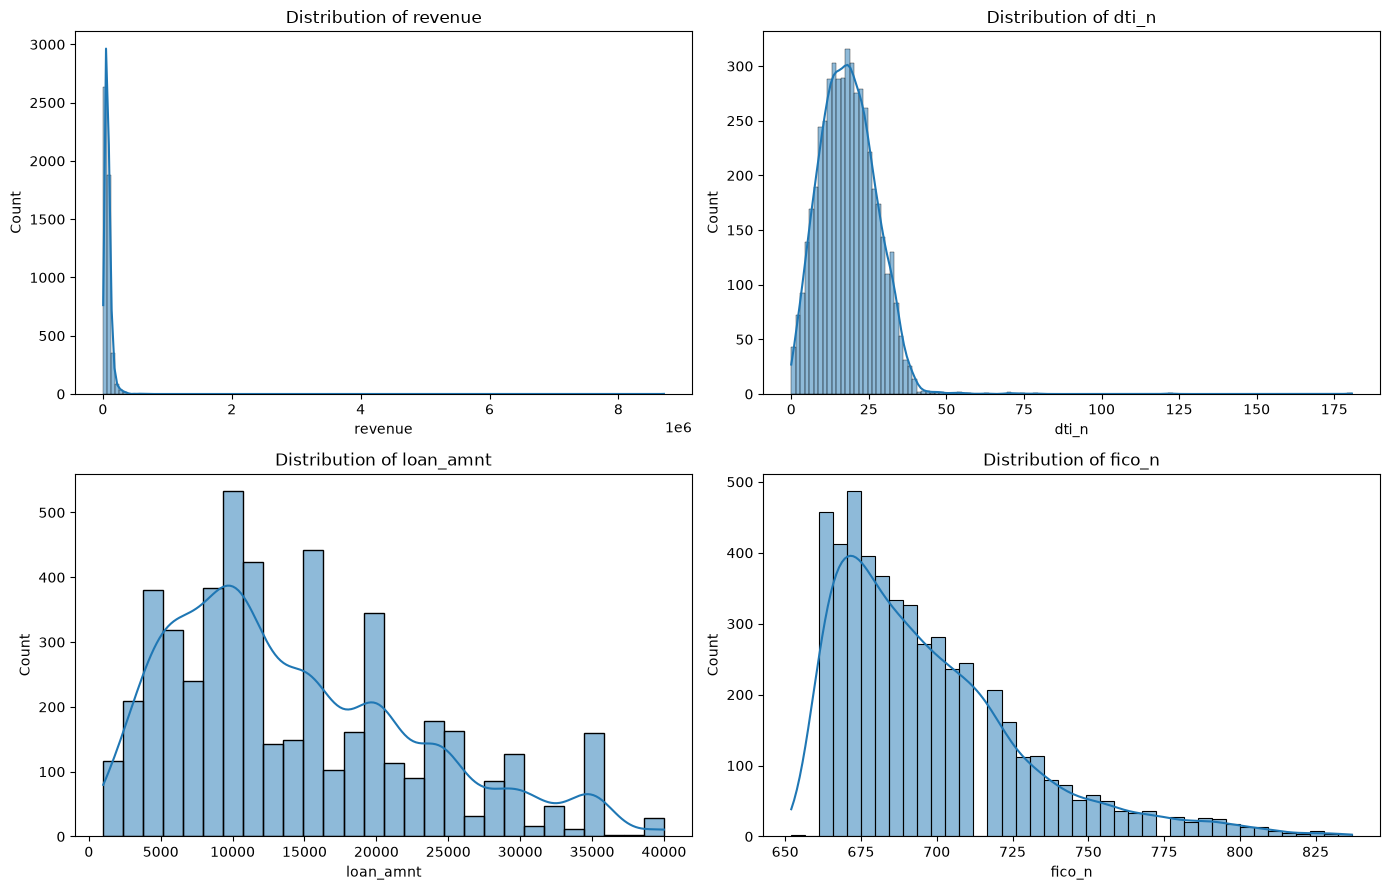

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

normality_sample = df[statistical_features].sample(
    n=5000,
    random_state=42
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for feature, ax in zip(statistical_features, axes.flatten()):
    sns.histplot(
        normality_sample[feature],
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

### Normality Assessment — Business Interpretation

- Revenue shows an extremely right-skewed distribution.
- DTI shows a long right tail with a concentration of observations around lower-to-middle values.
- Loan amount has multiple peaks, reflecting commonly requested loan amounts.
- FICO scores are concentrated around the mid-to-high 600s, with positive skewness.

The visual assessment suggests that none of the selected numerical variables follows a clear normal distribution.

This is an exploratory visual assessment, not a formal statistical normality test. Further statistical testing may be considered before selecting statistical methods.